<a href="https://colab.research.google.com/github/roshan-mahato/PRT_661_WILDFIRE_PREDICTION/blob/feature%2Fcomponents/Spatial_holdout_cont_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Repeated spatial holdouts and coordinate comparison

This extends the Assessment 3 notebook to complete the two planned experiments:
1. Compare LightGBM **with and without latitude/longitude predictors**.
2. Repeat the comparison across **five predefined allocations of 5° blocks**.

Coordinates remain available for partitioning and the 100 km test buffer in both variants. For each allocation, both models use exactly the same retained rows. Model settings and model random seed remain fixed. Calibration and F1 threshold selection use validation data only; test results are for reporting, not selecting the best seed.

#1. Setup

In [3]:
from datetime import datetime, timezone
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import gc
import hashlib
import importlib.metadata
import platform
import sys


RANDOM_STATE = 42  # Fixed model seed
EARTH_RADIUS_KM = 6371.0088
CALIBRATION_BINS = np.linspace(0.0, 1.0, 11)

#excluding fields that could leak fire info
EXCLUDED_PREDICT_FEATURES = {"acq_time", "brightness", "bright_ti4", "bright_ti5", "confidence",
    "days_since_cell_start", "days_to_nearest_fire", "frp", "instrument","label", "satellite", "scan", "track", "type"}


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#2. Config

In [6]:
DATA_DIR = Path('/content/drive/MyDrive/DataScience_Spatial Holdouts')
DATASET_PATH = DATA_DIR / 'final_dataset.csv'
METADATA_PATH = DATA_DIR / 'best_fire_model_metadata.json'
OUTPUT_ROOT = DATA_DIR / 'assessment4_results'

BLOCK_DEGREES = 5.0
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20
BUFFER_KM = 100.0
SPLIT_SEEDS = [42, 123, 2026, 7, 99]
RUN_MODEL = True  # False audits all splits without training models.
VARIANTS = {'with_coordinates': False, 'without_coordinates': True}

RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Results folder:', RUN_DIR)


Results folder: /content/drive/MyDrive/DataScience_Spatial Holdouts/assessment4_results/20261018T153145_493632Z


## 3. Dataset validation
The original feature contract, leakage exclusions, rain cap, model hyperparameters, isotonic calibration, and train-only near-fire exclusion are retained from the prev Spatial Holdouts Notebook. Required fields, labels, dates, coordinates, duplicate cell-days and predictor finiteness are checked. Split fractions refer to occupied blocks, so row fractions can differ.

The 100 km buffer is measured to the nearest observed test cell, rather than to the geometric edge of a block. There is no additional buffer between training and validation. Matching start/end dates verifies date ranges, not complete daily coverage for every cell.


In [7]:
def load_model_contract(path: Path, drop_location: bool) -> tuple[list[str], float, int]:
    if not path.is_file():
        raise FileNotFoundError(f"Model metadata was not found: {path}")
    with path.open(encoding="utf-8") as stream:
        metadata = json.load(stream)

    features = metadata.get("features")
    if not isinstance(features, list) or not features or not all(isinstance(x, str) for x in features):
        raise ValueError("Model metadata must contain a non-empty string list named 'features'.")
    if len(features) != len(set(features)):
        raise ValueError("Model metadata contains duplicate feature names.")

    forbidden = sorted(set(features) & EXCLUDED_PREDICT_FEATURES)
    if forbidden:
        raise ValueError(f"The model contract contains leakage features: {forbidden}")
    if drop_location:
        features = [name for name in features if name not in {"lat_round", "lon_round"}]
    if not features:
        raise ValueError("No predictors remain after applying the requested exclusions.")

    rain_cap = float(metadata.get("days_since_rain_cap", 180.0))
    near_fire_days = int(metadata.get("train_buffer_days", 1))
    if rain_cap <= 0.0 or near_fire_days < 0:
        raise ValueError("Invalid rain cap or training buffer in model metadata.")
    return features, rain_cap, near_fire_days


def load_dataset(path: Path, features: list[str], rain_cap: float) -> tuple[pd.DataFrame, int]:
    if not path.is_file():
        raise FileNotFoundError(f"Labelled dataset was not found: {path}")

    required = list(dict.fromkeys(
        features + ["lat_round", "lon_round", "acq_date", "label", "days_to_nearest_fire"]
    ))
    available = pd.read_csv(path, nrows=0).columns.tolist()
    missing = [name for name in required if name not in available]
    if missing:
        raise ValueError(f"Dataset is missing required columns: {missing}")

    numeric = [name for name in required if name != "acq_date"]
    data = pd.read_csv(path, usecols=required, dtype={name: "float32" for name in numeric})
    data["acq_date"] = pd.to_datetime(data["acq_date"], errors="coerce")

    missing_counts = data[required].isna().sum()
    missing_counts = missing_counts[missing_counts > 0]
    if not missing_counts.empty:
        raise ValueError(f"Dataset contains missing or invalid values: {missing_counts.to_dict()}")
    if not data["label"].isin([0.0, 1.0]).all():
        raise ValueError("The label column must contain only 0 and 1.")
    data["label"] = data["label"].astype("int8")

    if not data["lat_round"].between(-90.0, 90.0).all():
        raise ValueError("Latitude values fall outside [-90, 90].")
    if not data["lon_round"].between(-180.0, 180.0).all():
        raise ValueError("Longitude values fall outside [-180, 180].")
    if data.duplicated(["lat_round", "lon_round", "acq_date"]).any():
        raise ValueError("Dataset contains duplicate grid-cell/day rows.")

    if "month_sin" in features:
        data["month_sin"] = np.sin(2.0 * np.pi * data["acq_date"].dt.month / 12.0).astype("float32")
    if "month_cos" in features:
        data["month_cos"] = np.cos(2.0 * np.pi * data["acq_date"].dt.month / 12.0).astype("float32")

    capped_rows = 0
    if "days_since_rain" in features:
        capped_rows = int((data["days_since_rain"] > rain_cap).sum())
        data["days_since_rain"] = data["days_since_rain"].clip(upper=rain_cap)
    if not np.isfinite(data[features].to_numpy(copy=False)).all():
        raise ValueError("One or more predictors contain infinite values.")
    return data, capped_rows


In [8]:
def spatial_block_ids(
    latitude: np.ndarray,
    longitude: np.ndarray,
    block_degrees: float,
) -> tuple[np.ndarray, int]:
    latitude_bin = np.floor((latitude + 90.0) / block_degrees).astype("int32")
    longitude_bin = np.floor((longitude + 180.0) / block_degrees).astype("int32")
    longitude_bin_count = math.ceil(360.0 / block_degrees) + 1
    return latitude_bin * longitude_bin_count + longitude_bin, longitude_bin_count


def cell_codes(latitude: np.ndarray, longitude: np.ndarray) -> np.ndarray:
    latitude_key = np.rint((latitude + 90.0) * 1000.0).astype("int64")
    longitude_key = np.rint((longitude + 180.0) * 1000.0).astype("int64")
    return latitude_key * 1_000_000 + longitude_key


def block_bounds(block_ids: np.ndarray, block_degrees: float, longitude_bin_count: int) -> list[dict]:
    bounds = []
    for block_id in np.sort(block_ids):
        latitude_bin = int(block_id) // longitude_bin_count
        longitude_bin = int(block_id) % longitude_bin_count
        latitude_min = latitude_bin * block_degrees - 90.0
        longitude_min = longitude_bin * block_degrees - 180.0
        bounds.append({
            "block_id": int(block_id),
            "latitude_min": latitude_min,
            "latitude_max": min(latitude_min + block_degrees, 90.0),
            "longitude_min": longitude_min,
            "longitude_max": min(longitude_min + block_degrees, 180.0),
        })
    return bounds


def assign_blocks(
    occupied_blocks: np.ndarray,
    test_fraction: float,
    validation_fraction: float,
    random_state: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    block_count = len(occupied_blocks)
    if block_count < 3:
        raise ValueError("At least three occupied spatial blocks are required.")

    test_count = max(1, int(round(block_count * test_fraction)))
    validation_count = max(1, int(round(block_count * validation_fraction)))
    if test_count + validation_count >= block_count:
        raise ValueError("The requested fractions leave no training blocks.")

    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(np.sort(occupied_blocks))
    test_blocks = np.sort(shuffled[:test_count])
    validation_blocks = np.sort(shuffled[test_count:test_count + validation_count])
    train_blocks = np.sort(shuffled[test_count + validation_count:])
    return train_blocks, validation_blocks, test_blocks


def distance_to_test_cells(cells: pd.DataFrame, test_blocks: np.ndarray) -> np.ndarray:
    from sklearn.neighbors import BallTree

    test_cells = cells[cells["block_id"].isin(test_blocks)]
    if test_cells.empty:
        raise ValueError("No cells were assigned to the spatial test blocks.")
    test_radians = np.deg2rad(test_cells[["lat_round", "lon_round"]].to_numpy())
    all_radians = np.deg2rad(cells[["lat_round", "lon_round"]].to_numpy())
    distance, _ = BallTree(test_radians, metric="haversine").query(all_radians, k=1)
    return distance[:, 0] * EARTH_RADIUS_KM


def make_spatial_masks(
    data: pd.DataFrame,
    block_degrees: float,
    test_fraction: float,
    validation_fraction: float,
    buffer_km: float,
    random_state: int,
) -> tuple[dict[str, np.ndarray], dict]:
    latitude = data["lat_round"].to_numpy()
    longitude = data["lon_round"].to_numpy()
    row_blocks, longitude_bin_count = spatial_block_ids(latitude, longitude, block_degrees)
    row_cells = cell_codes(latitude, longitude)

    cells = data[["lat_round", "lon_round"]].drop_duplicates().copy()
    cells["block_id"], _ = spatial_block_ids(
        cells["lat_round"].to_numpy(), cells["lon_round"].to_numpy(), block_degrees
    )
    cells["cell_code"] = cell_codes(
        cells["lat_round"].to_numpy(), cells["lon_round"].to_numpy()
    )
    train_blocks, validation_blocks, test_blocks = assign_blocks(
        cells["block_id"].unique(), test_fraction, validation_fraction, random_state
    )

    cells["distance_to_test_km"] = distance_to_test_cells(cells, test_blocks)
    test_cell_mask = cells["block_id"].isin(test_blocks)
    development_far_enough = cells["distance_to_test_km"] > buffer_km

    train_cells = cells.loc[
        cells["block_id"].isin(train_blocks) & development_far_enough, "cell_code"
    ].to_numpy(dtype="int64")
    validation_cells = cells.loc[
        cells["block_id"].isin(validation_blocks) & development_far_enough, "cell_code"
    ].to_numpy(dtype="int64")
    test_cells = cells.loc[test_cell_mask, "cell_code"].to_numpy(dtype="int64")

    masks = {
        "train": np.isin(row_cells, train_cells),
        "validation": np.isin(row_cells, validation_cells),
        "test": np.isin(row_cells, test_cells),
    }
    if np.any(masks["train"] & masks["validation"]):
        raise RuntimeError("A cell appears in both training and validation.")
    if np.any(masks["train"] & masks["test"]) or np.any(masks["validation"] & masks["test"]):
        raise RuntimeError("A test cell appears in a development partition.")

    for name, mask in masks.items():
        if not mask.any():
            raise ValueError(f"The {name} partition is empty.")
        if data.loc[mask, "label"].nunique() != 2:
            raise ValueError(
                f"The {name} partition contains one class. Change the seed or block size."
            )

    development_cells = cells[cells["block_id"].isin(np.r_[train_blocks, validation_blocks])]
    excluded_by_buffer = int((development_cells["distance_to_test_km"] <= buffer_km).sum())
    kept_development = development_cells[development_cells["distance_to_test_km"] > buffer_km]
    minimum_distance = float(kept_development["distance_to_test_km"].min())

    details = {
        "block_degrees": block_degrees,
        "requested_test_fraction": test_fraction,
        "requested_validation_fraction": validation_fraction,
        "occupied_blocks": int(cells["block_id"].nunique()),
        "train_blocks": block_bounds(train_blocks, block_degrees, longitude_bin_count),
        "validation_blocks": block_bounds(validation_blocks, block_degrees, longitude_bin_count),
        "test_blocks": block_bounds(test_blocks, block_degrees, longitude_bin_count),
        "all_cells": int(len(cells)),
        "train_cells_after_buffer": int(len(train_cells)),
        "validation_cells_after_buffer": int(len(validation_cells)),
        "test_cells": int(len(test_cells)),
        "development_cells_excluded_by_buffer": excluded_by_buffer,
        "buffer_km": buffer_km,
        "minimum_development_to_test_distance_km": minimum_distance,
    }
    return masks, details


def apply_training_buffer(
    data: pd.DataFrame,
    train_mask: np.ndarray,
    near_fire_days: int,
) -> tuple[np.ndarray, int]:
    if near_fire_days == 0:
        return train_mask.copy(), 0
    labels = data["label"].to_numpy()
    distance = data["days_to_nearest_fire"].to_numpy()
    near_fire_negative = (
        train_mask & (labels == 0) & (distance > 0) & (distance <= near_fire_days)
    )
    fit_mask = train_mask & ~near_fire_negative
    if data.loc[fit_mask, "label"].nunique() != 2:
        raise ValueError("The near-fire buffer removed one class from training.")
    return fit_mask, int(near_fire_negative.sum())


def split_summary(data: pd.DataFrame, mask: np.ndarray, block_degrees: float) -> dict:
    subset = data.loc[mask, ["lat_round", "lon_round", "acq_date", "label"]]
    blocks, _ = spatial_block_ids(
        subset["lat_round"].to_numpy(), subset["lon_round"].to_numpy(), block_degrees
    )
    return {
        "rows": int(len(subset)),
        "cells": int(subset[["lat_round", "lon_round"]].drop_duplicates().shape[0]),
        "spatial_blocks": int(np.unique(blocks).size),
        "start_date": subset["acq_date"].min().date().isoformat(),
        "end_date": subset["acq_date"].max().date().isoformat(),
        "positive_rows": int(subset["label"].sum()),
        "positive_rate": float(subset["label"].mean()),
    }


In [9]:
def train_model(features: list[str], data: pd.DataFrame, masks: dict[str, np.ndarray]):
    import lightgbm as lgb
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.frozen import FrozenEstimator

    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=30,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    )
    model.fit(data.loc[masks["fit_train"], features], data.loc[masks["fit_train"], "label"])
    calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="isotonic")
    calibrated.fit(
        data.loc[masks["validation"], features], data.loc[masks["validation"], "label"]
    )
    return model, calibrated


def predict_partition(
    model,
    features: list[str],
    data: pd.DataFrame,
    mask: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    labels = data.loc[mask, "label"].to_numpy()
    probabilities = model.predict_proba(data.loc[mask, features])[:, 1]
    return labels, probabilities


def choose_f1_threshold(labels: np.ndarray, probabilities: np.ndarray) -> float:
    from sklearn.metrics import precision_recall_curve

    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    if len(thresholds) == 0:
        raise ValueError("Validation predictions do not provide a usable threshold.")
    f1 = 2.0 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[int(np.nanargmax(f1[:-1]))])


def evaluate(labels: np.ndarray, probabilities: np.ndarray, threshold: float, name: str) -> dict:
    from sklearn.metrics import (
        accuracy_score, average_precision_score, balanced_accuracy_score,
        brier_score_loss, confusion_matrix, f1_score, precision_score,
        recall_score, roc_auc_score,
    )

    predictions = (probabilities >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        "split": name,
        "threshold": float(threshold),
        "base_rate": float(labels.mean()),
        "mean_predicted": float(probabilities.mean()),
        "brier": float(brier_score_loss(labels, probabilities)),
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision_fire": float(precision_score(labels, predictions, zero_division=0)),
        "recall_fire": float(recall_score(labels, predictions, zero_division=0)),
        "f1_fire": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "pr_auc": float(average_precision_score(labels, probabilities)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def reliability_table(labels: np.ndarray, probabilities: np.ndarray) -> list[dict]:
    bins = pd.cut(probabilities, CALIBRATION_BINS, include_lowest=True)
    table = (
        pd.DataFrame({"bin": bins, "predicted": probabilities, "observed": labels})
        .groupby("bin", observed=True)
        .agg(rows=("observed", "size"), predicted=("predicted", "mean"),
             observed=("observed", "mean"))
        .reset_index()
    )
    table["bin"] = table["bin"].astype(str)
    return table.to_dict(orient="records")


def gain_importance(model, features: list[str]) -> list[dict]:
    gain = model.booster_.feature_importance(importance_type="gain")
    total = float(gain.sum())
    share = gain / total if total > 0.0 else np.zeros_like(gain, dtype=float)
    order = np.argsort(gain)[::-1]
    return [
        {"feature": features[index], "gain": float(gain[index]),
         "gain_share": float(share[index])}
        for index in order
    ]


def write_results(path: Path, results: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as stream:
        json.dump(results, stream, indent=2, allow_nan=False)
        stream.write("\n")


## 4. Load once and record reproducibility information
The two configurations share one loaded dataframe. Removing coordinates changes only the predictor list. Dataset SHA-256 is calculated in chunks; it records which exact file was used without loading another copy into memory

In [10]:
features_with, rain_cap, near_fire_days = load_model_contract(METADATA_PATH, False)
features_without, _, _ = load_model_contract(METADATA_PATH, True)
if not {'lat_round', 'lon_round'}.issubset(features_with):
    raise ValueError('The metadata must include both coordinate predictors for this comparison.')
feature_sets = {'with_coordinates': features_with, 'without_coordinates': features_without}
data, capped_rows = load_dataset(DATASET_PATH, features_with, rain_cap)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

manifest = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': str(DATASET_PATH), 'dataset_sha256': sha256_file(DATASET_PATH),
    'metadata': str(METADATA_PATH), 'metadata_sha256': sha256_file(METADATA_PATH),
    'rows': len(data), 'feature_sets': feature_sets,
    'split_seeds': SPLIT_SEEDS, 'model_seed': RANDOM_STATE,
    'block_degrees': BLOCK_DEGREES, 'buffer_km': BUFFER_KM,
    'test_fraction': TEST_FRACTION, 'validation_fraction': VALIDATION_FRACTION,
    'rain_cap': rain_cap, 'rain_rows_capped': capped_rows,
    'train_near_fire_buffer_days': near_fire_days, 'run_model': RUN_MODEL,
    'python': platform.python_version(),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
if RUN_MODEL:
    manifest['packages']['lightgbm'] = importlib.metadata.version('lightgbm')
write_results(RUN_DIR / 'manifest.json', manifest)
print(f'Loaded {len(data):,} rows; predictors: {len(features_with)} with / {len(features_without)} without coordinates.')


Loaded 2,869,583 rows; predictors: 27 with / 25 without coordinates.


## 5. Run paired experiments
Five split seeds × two feature variants = ten fits. A seed defines a block allocation, not a model seed. Each pair shares masks and the train-only near-fire exclusion. The F1 threshold is chosen separately for each calibrated model on its validation predictions.

Validation data are reused for calibration and threshold selection, as in the prev Spatial Holdouts nb. Consequently validation scores are development scores; spatial test scores provide the held-out evaluation. Invalid splits stop with an error instead of silently substituting another seed. Partial completed results remain saved.


In [11]:
metric_rows, audit_rows = [], []
for split_seed in SPLIT_SEEDS:
    print(f'Allocation seed {split_seed}', flush=True)
    masks, spatial_details = make_spatial_masks(
        data, BLOCK_DEGREES, TEST_FRACTION, VALIDATION_FRACTION,
        BUFFER_KM, split_seed,
    )
    masks['fit_train'], removed_near_fire = apply_training_buffer(
        data, masks['train'], near_fire_days,
    )
    summaries = {name: split_summary(data, mask, BLOCK_DEGREES)
                 for name, mask in masks.items()}
    date_ranges = {(summaries[name]['start_date'], summaries[name]['end_date'])
                   for name in ('train', 'validation', 'test')}
    if len(date_ranges) != 1:
        raise ValueError(f'Seed {split_seed}: partitions have different date ranges.')
    if spatial_details['minimum_development_to_test_distance_km'] <= BUFFER_KM:
        raise RuntimeError(f'Seed {split_seed}: test buffer was violated.')
    split_id = hashlib.sha256(np.packbits(masks['test']).tobytes()).hexdigest()
    audit = {'split_seed': split_seed, 'test_mask_sha256': split_id,
             'spatial_holdout': spatial_details, 'splits': summaries,
             'train_near_fire_negatives_removed': removed_near_fire}
    write_results(RUN_DIR / f'split_{split_seed}.json', audit)
    for name, summary in summaries.items():
        audit_rows.append({'split_seed': split_seed, 'partition': name, **summary,
                           'minimum_distance_km': spatial_details['minimum_development_to_test_distance_km'],
                           'test_mask_sha256': split_id})
    pd.DataFrame(audit_rows).to_csv(RUN_DIR / 'split_audit.csv', index=False)

    # Save one map per allocation using unique cells, not millions of rows.
    fig, axis = plt.subplots(figsize=(8, 6))
    for name, colour in [('train', '#4C78A8'), ('validation', '#E0AC20'), ('test', '#E45756')]:
        locations = data.loc[masks[name], ['lat_round', 'lon_round']].drop_duplicates()
        axis.scatter(locations.lon_round, locations.lat_round, s=8, alpha=0.7,
                     label=name, color=colour)
    axis.set(title=f'Spatial allocation — seed {split_seed}', xlabel='Longitude', ylabel='Latitude')
    axis.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / f'split_{split_seed}.png', dpi=150)
    plt.close(fig)
    if not RUN_MODEL:
        continue

    for variant, features in feature_sets.items():
        print(f'  Training {variant}', flush=True)
        base_model, calibrated_model = train_model(features, data, masks)
        val_labels, val_probs = predict_partition(calibrated_model, features, data, masks['validation'])
        threshold = choose_f1_threshold(val_labels, val_probs)
        test_labels, test_probs = predict_partition(calibrated_model, features, data, masks['test'])
        run_metrics = []
        for partition, labels, probs in [('validation', val_labels, val_probs), ('test', test_labels, test_probs)]:
            for rule, cutoff in [('default', 0.5), ('validation_f1', threshold)]:
                row = {'split_seed': split_seed, 'variant': variant,
                       'partition': partition, 'threshold_rule': rule,
                       'n_features': len(features), 'test_mask_sha256': split_id,
                       **evaluate(labels, probs, cutoff, partition)}
                run_metrics.append(row)
        write_results(RUN_DIR / f'model_{split_seed}_{variant}.json', {
            'split_seed': split_seed, 'variant': variant, 'features': features,
            'threshold_f1_optimal_on_validation': threshold, 'metrics': run_metrics,
            'test_reliability': reliability_table(test_labels, test_probs),
            'feature_gain_importance': gain_importance(base_model, features),
        })
        metric_rows.extend(run_metrics)
        pd.DataFrame(metric_rows).to_csv(RUN_DIR / 'all_metrics.csv', index=False)
        del base_model, calibrated_model, val_labels, val_probs, test_labels, test_probs
        gc.collect()

print('Completed all requested allocations. Results:', RUN_DIR)
display(pd.DataFrame(audit_rows))


Allocation seed 42
  Training with_coordinates
  Training without_coordinates
Allocation seed 123
  Training with_coordinates
  Training without_coordinates
Allocation seed 2026
  Training with_coordinates
  Training without_coordinates
Allocation seed 7
  Training with_coordinates
  Training without_coordinates
Allocation seed 99
  Training with_coordinates
  Training without_coordinates
Completed all requested allocations. Results: /content/drive/MyDrive/DataScience_Spatial Holdouts/assessment4_results/20261018T153145_493632Z


,split_seed,partition,rows,cells,spatial_blocks,start_date,end_date,positive_rows,positive_rate,minimum_distance_km,test_mask_sha256
0,42,train,1582734,1578,28,2024-01-01,2026-09-29,112547,0.071109,100.776168,a944c979f771182136f8e82fd45c34f8849d8116dacd94...
1,42,validation,491470,490,9,2024-01-01,2026-09-29,27800,0.056565,100.776168,a944c979f771182136f8e82fd45c34f8849d8116dacd94...
2,42,test,548641,547,10,2024-01-01,2026-09-29,44922,0.081879,100.776168,a944c979f771182136f8e82fd45c34f8849d8116dacd94...
3,42,fit_train,1503857,1578,28,2024-01-01,2026-09-29,112547,0.074839,100.776168,a944c979f771182136f8e82fd45c34f8849d8116dacd94...
4,123,train,1508512,1504,28,2024-01-01,2026-09-29,123553,0.081904,100.362239,55065926d10bff8120807eb7bfa372e3e62a6503651c7d...
5,123,validation,611830,610,10,2024-01-01,2026-09-29,43394,0.070925,100.362239,55065926d10bff8120807eb7bfa372e3e62a6503651c7d...
6,123,test,514539,513,10,2024-01-01,2026-09-29,23356,0.045392,100.362239,55065926d10bff8120807eb7bfa372e3e62a6503651c7d...
7,123,fit_train,1423322,1504,28,2024-01-01,2026-09-29,123553,0.086806,100.362239,55065926d10bff8120807eb7bfa372e3e62a6503651c7d...
8,2026,train,1326969,1323,27,2024-01-01,2026-09-29,86985,0.065552,100.362239,d774606334f6f96ecf998b32f07a68df76314ca84b8481...
9,2026,validation,546635,545,10,2024-01-01,2026-09-29,28202,0.051592,100.362239,d774606334f6f96ecf998b32f07a68df76314ca84b8481...


## 6. Test results and paired differences
Differences are **without coordinates minus with coordinates**, matched by split seed. Positive ROC-AUC, average precision (labelled `pr_auc` for continuity), precision, recall or F1 differences favour the model without coordinates. Negative Brier differences favour it.

Mean, sample standard deviation, minimum and maximum describe variation across these allocations. The repeated test sets may overlap; these are not independent trials or confidence intervals. Report all seeds and their fire base rates rather than selecting the most favourable allocation.


In [12]:
if RUN_MODEL:
    metrics = pd.DataFrame(metric_rows)
    test_results = metrics.loc[(metrics.partition == 'test') &
                               (metrics.threshold_rule == 'validation_f1')].copy()
    measures = ['roc_auc', 'pr_auc', 'brier', 'precision_fire', 'recall_fire', 'f1_fire']
    display(test_results[['split_seed', 'variant', 'base_rate', 'threshold'] + measures])
    summary = test_results.groupby('variant')[measures].agg(['mean', 'std', 'min', 'max'])
    summary.to_csv(RUN_DIR / 'test_summary.csv')
    display(summary)
    paired = test_results.pivot(index='split_seed', columns='variant', values=measures)
    differences = pd.DataFrame({
        measure: paired[(measure, 'without_coordinates')] - paired[(measure, 'with_coordinates')]
        for measure in measures
    })
    differences.to_csv(RUN_DIR / 'paired_differences_without_minus_with.csv')
    display(differences)
    display(differences.agg(['mean', 'std', 'min', 'max']))
    unique_allocations = pd.DataFrame(audit_rows).test_mask_sha256.nunique()
    print(f'Distinct test allocations: {unique_allocations} of {len(SPLIT_SEEDS)} requested seeds.')
    if unique_allocations < len(SPLIT_SEEDS):
        print('Some seeds produced identical test sets; report this limitation.')
else:
    print('Split audit only. Set RUN_MODEL=True and rerun to obtain model comparisons.')


,split_seed,variant,base_rate,threshold,roc_auc,pr_auc,brier,precision_fire,recall_fire,f1_fire
3,42,with_coordinates,0.081879,0.170550,0.742093,0.182284,0.071198,0.205429,0.408887,0.273466
7,42,without_coordinates,0.081879,0.156716,0.737661,0.177736,0.071309,0.197920,0.424157,0.269900
11,123,with_coordinates,0.045392,0.220155,0.834673,0.201913,0.040333,0.197256,0.340983,0.249929
15,123,without_coordinates,0.045392,0.191563,0.824981,0.188567,0.039813,0.235505,0.305917,0.266133
19,2026,with_coordinates,0.094630,0.180556,0.817725,0.286608,0.080801,0.230925,0.707587,0.348209
23,2026,without_coordinates,0.094630,0.175956,0.803765,0.265063,0.078526,0.227327,0.701727,0.343406
27,7,with_coordinates,0.057217,0.232397,0.738095,0.130093,0.060232,0.138010,0.450889,0.211334
31,7,without_coordinates,0.057217,0.214048,0.763223,0.151092,0.056634,0.153289,0.511113,0.235845
35,99,with_coordinates,0.066875,0.227453,0.754992,0.324030,0.053831,0.455342,0.306476,0.366365
39,99,without_coordinates,0.066875,0.177950,0.867541,0.311482,0.052618,0.322403,0.511318,0.395457


roc_auc                                  pr_auc  \
                         mean       std       min       max      mean   
variant                                                                 
with_coordinates     0.777516  0.045277  0.738095  0.834673  0.224986   
without_coordinates  0.799434  0.051081  0.737661  0.867541  0.218788   

                                                      brier            ...  \
                          std       min       max      mean       std  ...   
variant                                                                ...   
with_coordinates     0.079006  0.130093  0.324030  0.061279  0.015611  ...   
without_coordinates  0.066923  0.151092  0.311482  0.059780  0.015364  ...   

                    precision_fire           recall_fire                      \
                               min       max        mean       std       min   
variant                                                                        
with_coordinates          0.138010  0.455342    0.442964  0.158334  0.306476   
without_coordinates       0.153289  0.322403    0.490846  0.144868  0.305917   

                                f1_fire                                
                          max      mean       std       min       max  
variant                                                                
with_coordinates     0.707587  0.289861  0.065740  0.211334  0.366365  
without_coordinates  0.701727  0.302148  0.065464  0.235845  0.395457  

[2 rows x 24 columns]

,roc_auc,pr_auc,brier,precision_fire,recall_fire,f1_fire
split_seed,,,,,,
7,0.025128,0.020999,-0.003598,0.015278,0.060224,0.024511
42,-0.004432,-0.004548,0.000111,-0.007508,0.015271,-0.003566
99,0.112549,-0.012549,-0.001213,-0.132939,0.204841,0.029093
123,-0.009693,-0.013346,-0.000520,0.038250,-0.035066,0.016203
2026,-0.013960,-0.021545,-0.002274,-0.003598,-0.005860,-0.004803


,roc_auc,pr_auc,brier,precision_fire,recall_fire,f1_fire
mean,0.021918,-0.006198,-0.001499,-0.018103,0.047882,0.012288
std,0.052927,0.016350,0.001470,0.066708,0.094367,0.015737
min,-0.013960,-0.021545,-0.003598,-0.132939,-0.035066,-0.004803
max,0.112549,0.020999,0.000111,0.038250,0.204841,0.029093


Distinct test allocations: 5 of 5 requested seeds.


## 7. Compare performance across allocations


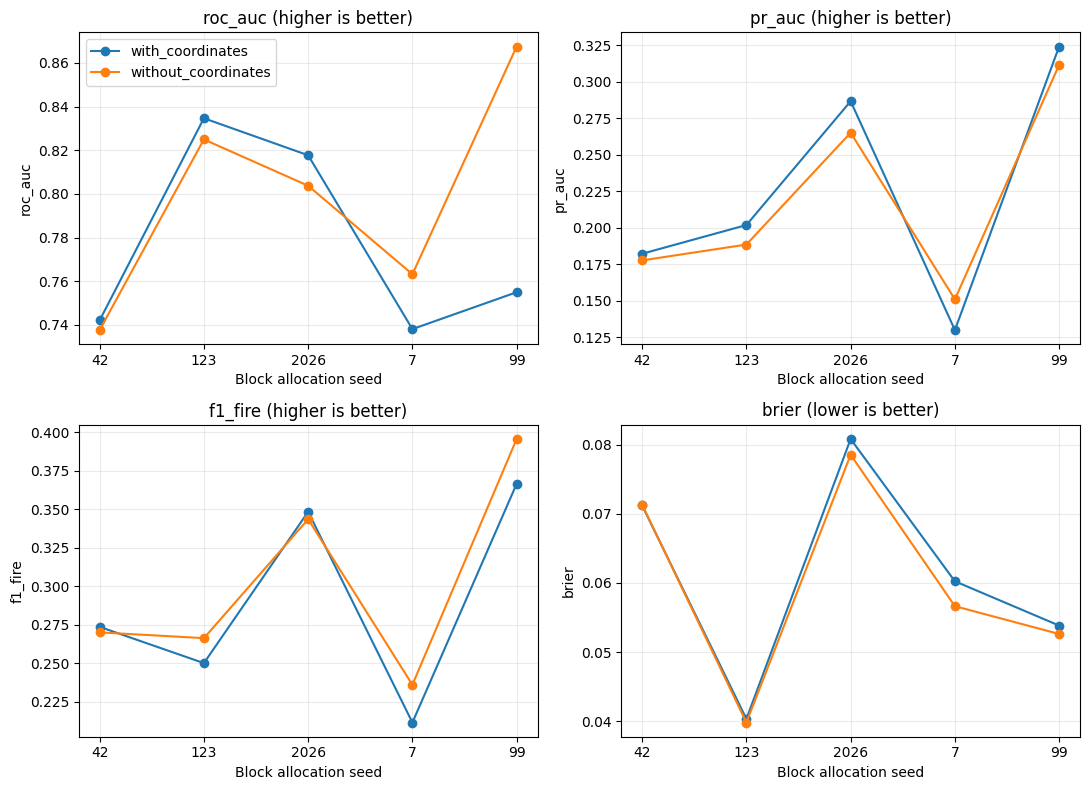

In [13]:
if RUN_MODEL:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for axis, measure in zip(axes.flat, ['roc_auc', 'pr_auc', 'f1_fire', 'brier']):
        for variant, group in test_results.groupby('variant', sort=False):
            ordered = group.set_index('split_seed').loc[SPLIT_SEEDS]
            axis.plot(range(len(SPLIT_SEEDS)), ordered[measure], marker='o', label=variant)
        axis.set_xticks(range(len(SPLIT_SEEDS)), [str(seed) for seed in SPLIT_SEEDS])
        axis.set(xlabel='Block allocation seed', ylabel=measure,
                 title=measure + (' (lower is better)' if measure == 'brier' else ' (higher is better)'))
        axis.grid(alpha=0.25)
    axes[0, 0].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'coordinate_comparison.png', dpi=180)
    plt.show()